In [1]:
import matplotlib.pyplot as plt
import numpy as np
import re

import sklearn

import multiphase_flow_utils
from multiphase_flow_utils import read_and_split_file

In [2]:
sklearn.set_config(transform_output='pandas')
files = [
    'combined_diagnostic.xlsx',
]
dataset_nums = ['Diagnostic']
ydata_col = 'Erro ([%])'

In [3]:
def units_and_description(df):
    split_names = [
        re.split(r'[()]',x) for x in df.columns.values.tolist()
    ]
    
    unit = []
    desc = []
    for split in split_names:
        desc += [split[0]]
        if len(split) > 2:
            unit += [split[1]]

        else:
            unit += ['no unit']
    return unit,desc

In [4]:
nplots = len(files)
subplots_args = (nplots,2)
subplot_kw = dict(
    figsize=(12,2*nplots+2.6),
    sharex='col',
    squeeze=False,
)

Erro ([%])
False
False
media_QMeter (m3_hr) media_FlowVelA (m_s)
QMeter media FlowVelA media
media_QMeter/FlowVelA (m2)
mediana_QMeter (m3_hr) mediana_FlowVelA (m_s)
QMeter mediana FlowVelA mediana
mediana_QMeter/FlowVelA (m2)
maximo_QMeter (m3_hr) maximo_FlowVelA (m_s)
QMeter maximo FlowVelA maximo
maximo_QMeter/FlowVelA (m2)
minimo_QMeter (m3_hr) minimo_FlowVelA (m_s)
QMeter minimo FlowVelA minimo
minimo_QMeter/FlowVelA (m2)
desvio_padrao_QMeter (m3_hr) desvio_padrao_FlowVelA (m_s)
QMeter desvio_padrao FlowVelA desvio_padrao
desvio_padrao_QMeter/FlowVelA (m2)
media_QMeter (m3_hr) media_FlowVelB (m_s)
QMeter media FlowVelB media
media_QMeter/FlowVelB (m2)
mediana_QMeter (m3_hr) mediana_FlowVelB (m_s)
QMeter mediana FlowVelB mediana
mediana_QMeter/FlowVelB (m2)
maximo_QMeter (m3_hr) maximo_FlowVelB (m_s)
QMeter maximo FlowVelB maximo
maximo_QMeter/FlowVelB (m2)
minimo_QMeter (m3_hr) minimo_FlowVelB (m_s)
QMeter minimo FlowVelB minimo
minimo_QMeter/FlowVelB (m2)
desvio_padrao_QMeter (m3

/home/dsheen/multiphase_flow/multiphase_flow_utils.py:93: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  xdata.insert(data_position,new_col_name,xdata[meter]/xdata[flow])


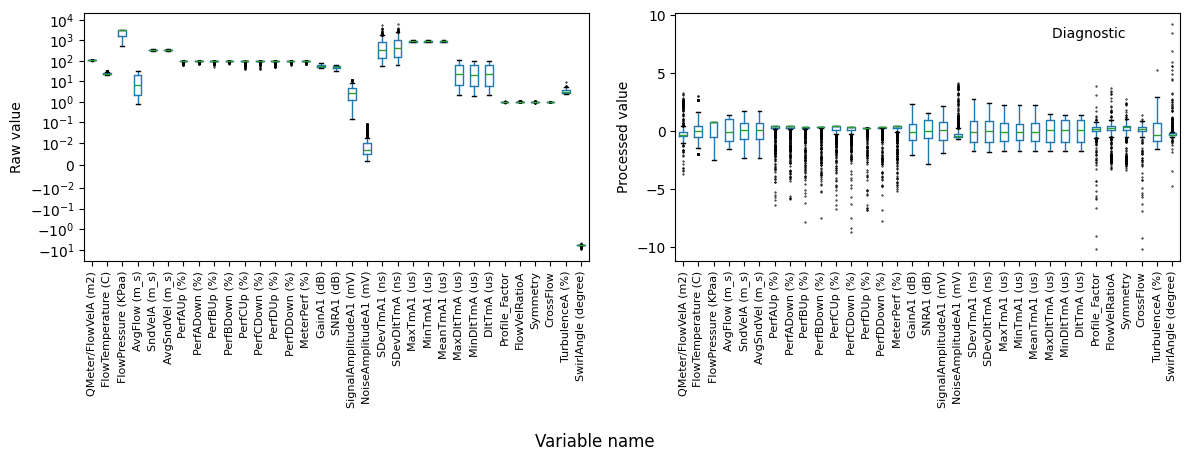

In [5]:
fig,axs = plt.subplots(
    *subplots_args,**subplot_kw
)

def logabs(x):
    return np.log1p(np.abs(x))

scal = sklearn.pipeline.Pipeline(
    steps=[
        ('log',sklearn.preprocessing.FunctionTransformer(logabs)),
        ('scaling',sklearn.preprocessing.StandardScaler(),)
    ]
)

for num,(file,ax_row,ds) in enumerate(zip(files,axs,dataset_nums)):
    all_x,all_y = read_and_split_file(
        file,ydata_col
    )
    
    print(all_x.shape)
    
    ax_row[0].set_ylabel('Raw value')
    ax_row[1].set_ylabel('Processed value')
    
    unit,description = units_and_description(all_x)
    mean_cols_mask = np.array([x.split('_')[0]=='media' for x in description])
    not_a_cols_mask = np.array([re.search(r'[BCD2]', x[-3:]) is not None for x in description])
    
    mean_x = all_x.drop(
        columns=all_x.columns.values[
            np.logical_or(~mean_cols_mask,not_a_cols_mask)
        ]
    )
    
    #ax_row[0].set_title('Unscaled')
#     ax_row[0].text(
#         0.9,0.9,'DS {}'.format(ds),
#         ha='right',
#         transform=ax_row[0].transAxes
#     )
    #all_x.boxplot(
    mean_x.boxplot(
        ax=ax_row[0],
        rot=90,
        grid=False,flierprops=dict(
            marker='.',color='0.2',markersize=1
        ),#orientation='horizontal'
    )
    ax_row[0].set_yscale('symlog',linthresh=0.01)
    
    #plt.xticks(fontsize=8)
    
    #ax_row[1].set_title('Scaled')
    ax_row[1].text(
        0.9,0.9,'{} '.format(ds),
        ha='right',
        transform=ax_row[1].transAxes
    )
    #scal.fit_transform(all_x).boxplot(
    scal.fit_transform(mean_x).boxplot(
        ax=ax_row[1],
        rot=90,
        grid=False,flierprops=dict(
            marker='.',color='0.2',markersize=1
        ),#orientation='horizontal'
    )
    
    #plt.xticks(fontsize=8)
labels = [x[6:] for x in mean_x.columns.values]

axs[-1,0].set_xticklabels(1*labels)
axs[-1,1].set_xticklabels(1*labels)

t=axs[-1,0].tick_params(axis='x',labelsize=8)
t=axs[-1,1].tick_params(axis='x',labelsize=8)

#fig.suptitle('With log')
fig.supxlabel('Variable name')

# t=axs[0,1].tick_params(
#     np.arange(len(all_x.T)),
#     labels=[]
# )

fig.tight_layout()

In [6]:
mean_x.columns.values

<StringArray>
[  'media_QMeter/FlowVelA (m2)',    'media_FlowTemperature (C)',
    'media_FlowPressure (KPaa)',          'media_AvgFlow (m_s)',
          'media_SndVelA (m_s)',        'media_AvgSndVel (m_s)',
            'media_PerfAUp (%)',          'media_PerfADown (%)',
            'media_PerfBUp (%)',          'media_PerfBDown (%)',
            'media_PerfCUp (%)',          'media_PerfCDown (%)',
            'media_PerfDUp (%)',          'media_PerfDDown (%)',
          'media_MeterPerf (%)',            'media_GainA1 (dB)',
             'media_SNRA1 (dB)', 'media_SignalAmplitudeA1 (mV)',
  'media_NoiseAmplitudeA1 (mV)',          'media_SDevTmA1 (ns)',
        'media_SDevDltTmA (ns)',           'media_MaxTmA1 (us)',
           'media_MinTmA1 (us)',          'media_MeanTmA1 (us)',
         'media_MaxDltTmA (us)',         'media_MinDltTmA (us)',
            'media_DltTmA (us)',         'media_Profile_Factor',
          'media_FlowVelRatioA',               'media_Symmetry',
           

Erro ([%])
False
False
media_QMeter (m3_hr) media_FlowVelA (m_s)
QMeter media FlowVelA media
media_QMeter/FlowVelA (m2)
mediana_QMeter (m3_hr) mediana_FlowVelA (m_s)
QMeter mediana FlowVelA mediana
mediana_QMeter/FlowVelA (m2)
maximo_QMeter (m3_hr) maximo_FlowVelA (m_s)
QMeter maximo FlowVelA maximo
maximo_QMeter/FlowVelA (m2)
minimo_QMeter (m3_hr) minimo_FlowVelA (m_s)
QMeter minimo FlowVelA minimo
minimo_QMeter/FlowVelA (m2)
desvio_padrao_QMeter (m3_hr) desvio_padrao_FlowVelA (m_s)
QMeter desvio_padrao FlowVelA desvio_padrao
desvio_padrao_QMeter/FlowVelA (m2)
media_QMeter (m3_hr) media_FlowVelB (m_s)
QMeter media FlowVelB media
media_QMeter/FlowVelB (m2)
mediana_QMeter (m3_hr) mediana_FlowVelB (m_s)
QMeter mediana FlowVelB mediana
mediana_QMeter/FlowVelB (m2)
maximo_QMeter (m3_hr) maximo_FlowVelB (m_s)
QMeter maximo FlowVelB maximo
maximo_QMeter/FlowVelB (m2)
minimo_QMeter (m3_hr) minimo_FlowVelB (m_s)
QMeter minimo FlowVelB minimo
minimo_QMeter/FlowVelB (m2)
desvio_padrao_QMeter (m3

/home/dsheen/multiphase_flow/multiphase_flow_utils.py:93: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  xdata.insert(data_position,new_col_name,xdata[meter]/xdata[flow])


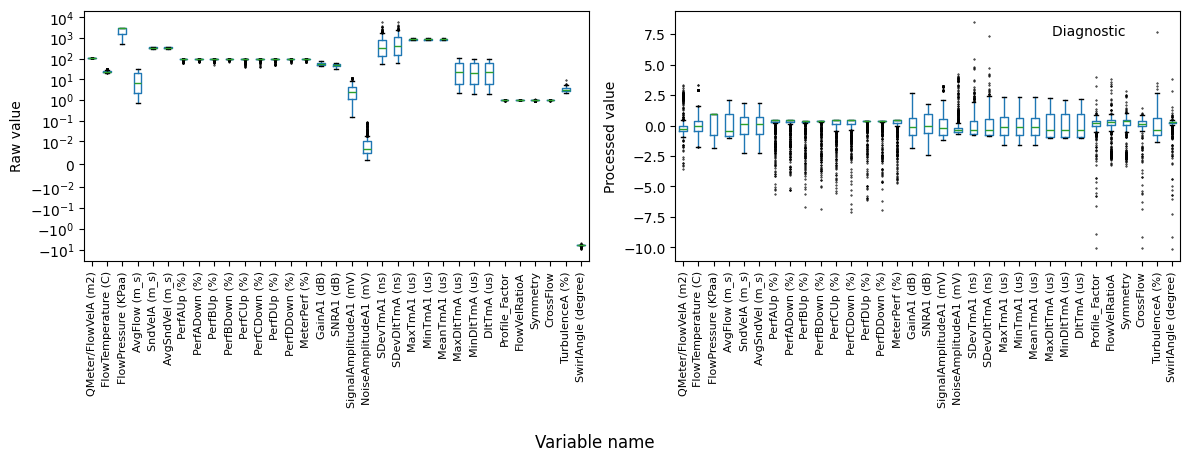

In [7]:
fig,axs = plt.subplots(
    *subplots_args,**subplot_kw
)

def logabs(x):
    return np.log1p(np.abs(x))

scal = sklearn.pipeline.Pipeline(
    steps=[
        #('log',sklearn.preprocessing.FunctionTransformer(logabs)),
        ('scaling',sklearn.preprocessing.StandardScaler(),)
    ]
)

for num,(file,ax_row,ds) in enumerate(zip(files,axs,dataset_nums)):
    all_x,all_y = read_and_split_file(
        file,ydata_col
    )
    
    ax_row[0].set_ylabel('Raw value')
    ax_row[1].set_ylabel('Processed value')
    
    unit,description = units_and_description(all_x)
    mean_cols_mask = np.array([x.split('_')[0]=='media' for x in description])
    not_a_cols_mask = np.array([re.search(r'[BCD2]', x[-3:]) is not None for x in description])
    
    mean_x = all_x.drop(
        columns=all_x.columns.values[
            np.logical_or(~mean_cols_mask,not_a_cols_mask)
        ]
    )
    
    #ax_row[0].set_title('Unscaled')
#     ax_row[0].text(
#         0.9,0.9,'DS {}'.format(ds),
#         ha='right',
#         transform=ax_row[0].transAxes
#     )
    #all_x.boxplot(
    mean_x.boxplot(
        ax=ax_row[0],
        rot=90,
        grid=False,flierprops=dict(
            marker='.',color='0.2',markersize=1
        ),#orientation='horizontal'
    )
    ax_row[0].set_yscale('symlog',linthresh=0.01)
    
    #plt.xticks(fontsize=8)
    
    #ax_row[1].set_title('Scaled')
    ax_row[1].text(
        0.9,0.9,'{} '.format(ds),
        ha='right',
        transform=ax_row[1].transAxes
    )
    #scal.fit_transform(all_x).boxplot(
    scal.fit_transform(mean_x).boxplot(
        ax=ax_row[1],
        rot=90,
        grid=False,flierprops=dict(
            marker='.',color='0.2',markersize=1
        ),#orientation='horizontal'
    )
    
    #plt.xticks(fontsize=8)
labels = [x[6:] for x in mean_x.columns.values]

axs[-1,0].set_xticklabels(1*labels)
axs[-1,1].set_xticklabels(1*labels)

t=axs[-1,0].tick_params(axis='x',labelsize=8)
t=axs[-1,1].tick_params(axis='x',labelsize=8)

#fig.suptitle('With log')
fig.supxlabel('Variable name')

# t=axs[0,1].tick_params(
#     np.arange(len(all_x.T)),
#     labels=[]
# )

fig.tight_layout()